# Teleportation Experiment 

In [2]:
# for api token 
import keyring as k3

print("Llibraries Loaded")


Llibraries Loaded


# Step 1 - Map your problem to a circuit 

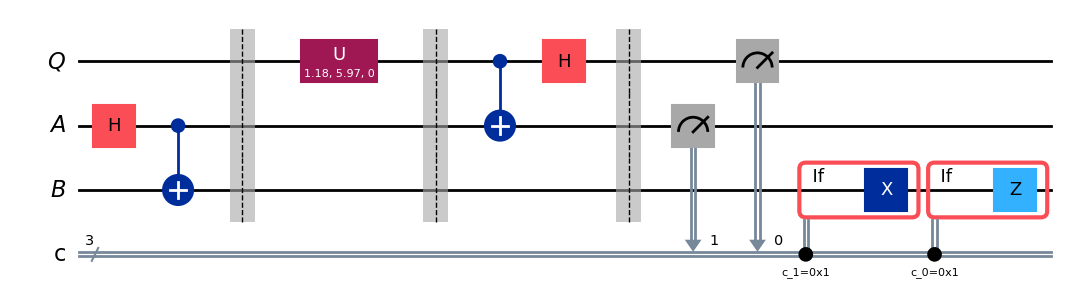

In [5]:
# Import some general packages
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
import random
import numpy as np
from numpy import pi

# Define registers
secret = QuantumRegister(1, "Q")
Alice = QuantumRegister(1, "A")
Bob = QuantumRegister(1, "B")

cr = ClassicalRegister(3, 'c')

qc = QuantumCircuit(secret, Alice, Bob, cr)

# We entangle Alice's and Bob's qubits as in our work above. We apply a Hadamard gate and then a CNOT gate.
# Note that the second argument in the CNOT gate is the target.
qc.h(Alice)
qc.cx(Alice,Bob)

# Inserting a barrier changes nothing about the logic. It just allows us to force gates to be positioned in "layers".
qc.barrier()

# Now we will use random variables to create the secret state. Don't worry about the "u" gate and the details. 
np.random.seed(42) #fixing seed for repeatibility
theta = np.random.uniform(0.0, 1.0) * np.pi    #from 0 to pi
varphi = np.random.uniform(0.0, 2.0) * np.pi    #from 0 to 2*pi

# Assign the secret state to the qubit on the other side of Alice's (qubit 0), labeled Q
qc.u(theta, varphi, 0.0, secret)
qc.barrier()

# Now entangle Q and Alice's qubits as in the discussion above.
qc.cx(secret,Alice)
qc.h(secret)
qc.barrier()

# Now Alice measures her qubits, and stores the outcomes in the "classical registers" cr[]
qc.measure(Alice, cr[1])
qc.measure(secret, cr[0])

# Now we insert some conditional logic. If Alice measures Q in a "1" we need a Z gate, and if Alice measures A in a "1" we need an X gate (see the table).
with qc.if_test((cr[1], 1)):
    qc.x(Bob)
with qc.if_test((cr[0], 1)):   
    qc.z(Bob)

qc.draw(output="mpl")

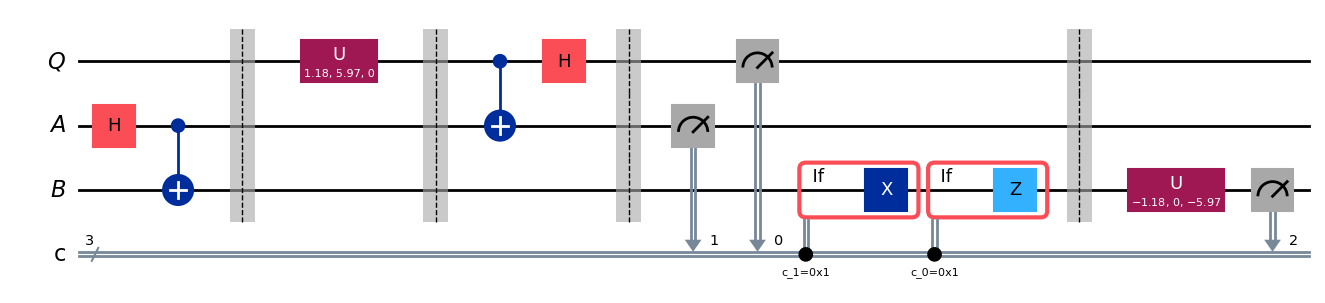

In [6]:
# Add the inverse of U and measure Bob's qubit.
qc.barrier()

qc.u(theta, varphi, 0.0, Bob).inverse()    # inverse of u(theta,varphi,0.0)
qc.measure(Bob, cr[2]) # add measurement gate

qc.draw(output="mpl")

# Step 2 - Optimize the circuit for the backend 

In [ ]:
# 2.1 - Get the backend from IBM Quantum

# Get the API token from keyring
api_token = k3.get_password('ibm_quantum', 'api_token')

#Load the Qiskit Runtime service
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService(channel="ibm_quantum", token=api_token)


#Use the least busy backend, or uncomment the loading of a specific backend like "ibm_brisbane".
backend = service.least_busy(operational=True, simulator=False, min_num_qubits = 127)
#backend = service.backend("ibm_brisbane")
print(backend.name)

ibm_sherbrooke


In [9]:
# Step 2.2: Transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)
qc_isa = pm.run(qc)

In [10]:
# Load the Runtime primitive and session
from qiskit_ibm_runtime import SamplerV2 as Sampler
sampler = Sampler(mode = backend)

# Step 3 - Execute the Circuit

In [11]:
# 3.1 Dispatch the job
job = sampler.run([qc_isa])
job_id = job.job_id()
print(f" > Job ID: {job_id}")
print("Job Created")


 > Job ID: d01wsged8drg008jfcrg
Job Created


In [ ]:
# 3.2 Wait for the job to finish
status = job.status()
print(f" > Job Status: {status}")


 > Job Status: DONE


In [ ]:
# 3.3 Fetch the results
res=job.result()
counts=res[0].data.c.get_counts()

# Step 4 - Post Processing 

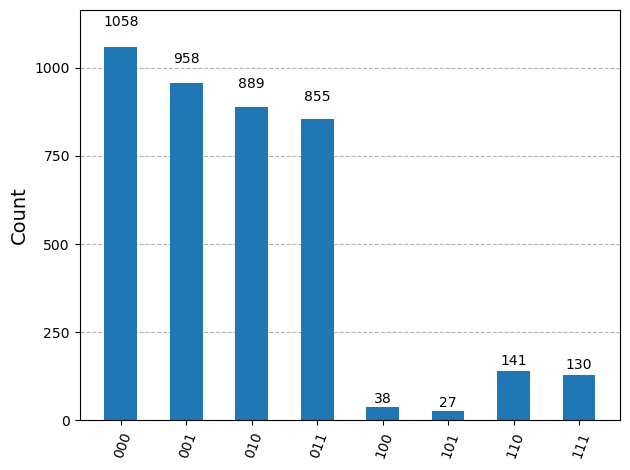

In [15]:
# 4.1 - Graph the results
from qiskit.visualization import plot_histogram
plot_histogram(counts)